# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

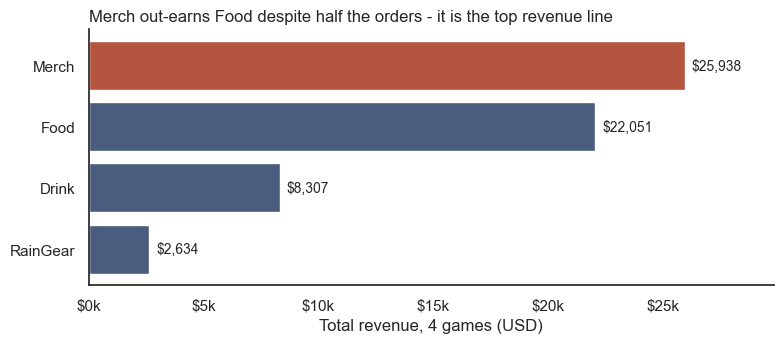

,revenue,orders
category,,
RainGear,2634.46,186
Drink,8307.43,1405
Food,22051.41,1851
Merch,25937.91,922


In [2]:
by_cat = df.groupby('category')['revenue'].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [RUST if c == by_cat.idxmax() else BLUE for c in by_cat.index]
ax.barh(by_cat.index, by_cat.values, color=colors)
for y, v in enumerate(by_cat.values):
    ax.text(v + 300, y, f'${v:,.0f}', va='center', fontsize=10)
ax.set_xlim(0, by_cat.max() * 1.15)
ax.xaxis.set_major_formatter(lambda x, _: f'${x / 1000:,.0f}k')
ax.tick_params(left=False)
finish(ax,
       'Merch out-earns Food despite half the orders - it is the top revenue line',
       xlabel='Total revenue, 4 games (USD)')
plt.show()

by_cat.to_frame('revenue').assign(orders=df['category'].value_counts())

**Caption:** Merch ($25.9k) edges out Food ($22.1k) on roughly half as many orders, so merch stock-outs cost more revenue than food stock-outs - protect merch inventory first.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

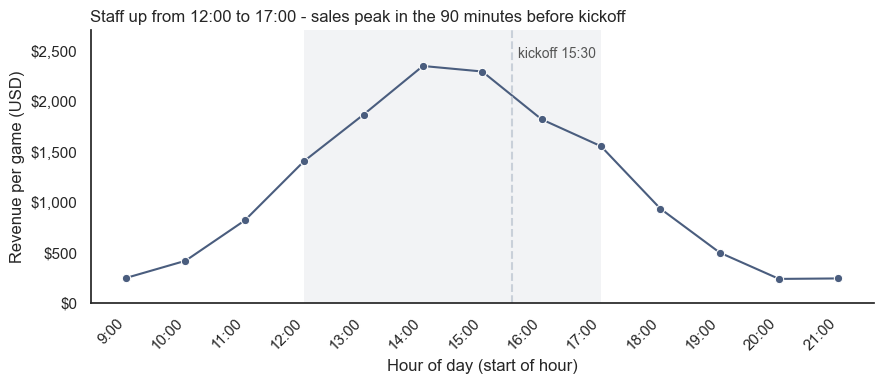

In [3]:
n_games = df['game'].nunique()
by_hour = df.groupby('hour')['revenue'].sum() / n_games   # average game

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(x=by_hour.index, y=by_hour.values, marker='o', color=BLUE, ax=ax)
ax.axvline(15.5, color=GRAY, ls='--', lw=1.5)
ax.text(15.6, by_hour.max() * 1.02, 'kickoff 15:30', color='#555', fontsize=10, va='bottom')
ax.axvspan(12, 17, color=BLUE, alpha=0.07, lw=0)
ax.set_ylim(0, by_hour.max() * 1.15)
ax.set_xticks(hours)
ax.set_xticklabels([f'{h}:00' for h in hours], rotation=45, ha='right')
ax.yaxis.set_major_formatter(lambda y, _: f'${y:,.0f}')
finish(ax,
       'Staff up from 12:00 to 17:00 - sales peak in the 90 minutes before kickoff',
       xlabel='Hour of day (start of hour)', ylabel='Revenue per game (USD)')
plt.show()

**Caption:** In an average game, hourly revenue climbs from about $1.4k at noon to a peak of about $2.4k at 14:00-15:00, then falls back below $1k by 19:00; schedule the full shift for 12:00-17:00 (shaded) and run a skeleton crew before and after.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

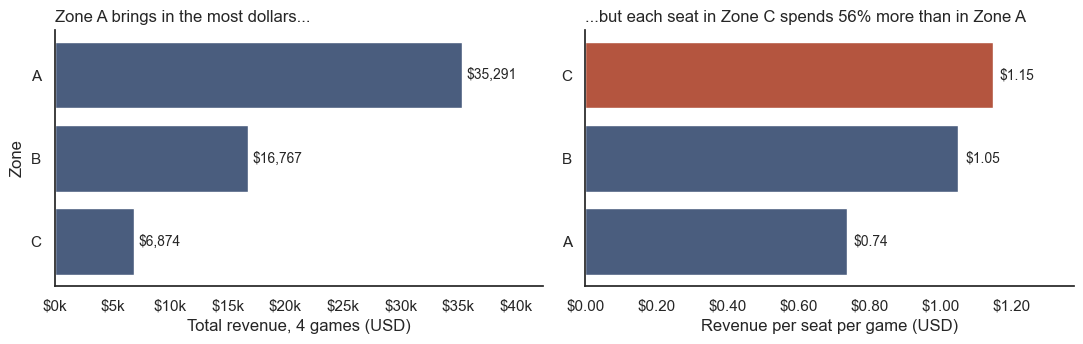

,revenue,capacity,per_seat_per_game
A,35290.90,12000,0.74
B,16766.58,4000,1.05
C,6873.73,1500,1.15


In [4]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
cap = pd.Series(zone_capacity)
n_games = df['game'].nunique()
raw = df.groupby('zone')['revenue'].sum()
per_seat = raw / cap / n_games                    # USD per seat per game
zones = pd.DataFrame({'revenue': raw, 'capacity': cap, 'per_seat_per_game': per_seat.round(2)})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)

r = raw.sort_values()
ax1.barh(r.index, r.values, color=BLUE)
for y, v in enumerate(r.values):
    ax1.text(v + 400, y, f'${v:,.0f}', va='center', fontsize=10)
ax1.set_xlim(0, r.max() * 1.2)
ax1.xaxis.set_major_formatter(lambda x, _: f'${x / 1000:,.0f}k')
ax1.tick_params(left=False)
finish(ax1, 'Zone A brings in the most dollars...', xlabel='Total revenue, 4 games (USD)', ylabel='Zone')

p = per_seat.sort_values()
ax2.barh(p.index, p.values, color=[RUST if z == p.idxmax() else BLUE for z in p.index])
for y, v in enumerate(p.values):
    ax2.text(v + 0.02, y, f'${v:.2f}', va='center', fontsize=10)
ax2.set_xlim(0, p.max() * 1.2)
ax2.xaxis.set_major_formatter(lambda x, _: f'${x:.2f}')
ax2.tick_params(left=False)
lift = p.max() / p.min() - 1
finish(ax2, f'...but each seat in Zone {p.idxmax()} spends {lift:.0%} more than in Zone {p.idxmin()}', xlabel='Revenue per seat per game (USD)')
plt.show()

zones

**Caption, and which panel I would present:** Zone A earns 2x Zone B and 5x Zone C in raw dollars, but that is mostly seat count: per seat, Zone C ($1.15/game) and B ($1.05) out-spend A ($0.74). For "where do we need the most registers and stock?" I would show the **raw** panel, because volume is what staff have to serve. For "where should we add a new stand or premium offering?" I would show the **per-seat** panel, because it measures demand per fan and A looks under-served.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

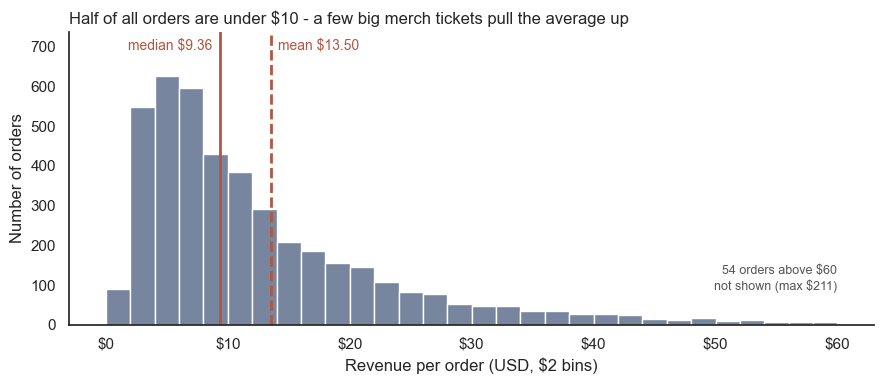

skew: 3.54   share of orders below the mean: 66%


In [5]:
med, mean = df['revenue'].median(), df['revenue'].mean()
cutoff = 60
n_hidden = (df['revenue'] > cutoff).sum()

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df.loc[df['revenue'] <= cutoff, 'revenue'], binwidth=2, binrange=(0, cutoff),
             color=BLUE, edgecolor='white', ax=ax)
ax.axvline(med, color=RUST, lw=2)
ax.axvline(mean, color=RUST, lw=2, ls='--')
top = ax.get_ylim()[1] * 1.12
ax.set_ylim(0, top)
ax.text(med - 0.6, top * 0.94, f'median ${med:.2f}', color=RUST, fontsize=10, ha='right')
ax.text(mean + 0.6, top * 0.94, f'mean ${mean:.2f}', color=RUST, fontsize=10)
ax.text(cutoff, top * 0.12, f'{n_hidden} orders above ${cutoff}\nnot shown (max ${df.revenue.max():.0f})',
        ha='right', fontsize=9, color='#555')
ax.xaxis.set_major_formatter(lambda x, _: f'${x:.0f}')
finish(ax,
       'Half of all orders are under $10 - a few big merch tickets pull the average up',
       xlabel='Revenue per order (USD, $2 bins)', ylabel='Number of orders')
plt.show()

print(f'skew: {df.revenue.skew():.2f}   share of orders below the mean: {(df.revenue < mean).mean():.0%}')

**Caption:** Order values are strongly right-skewed: the median order is $9.36 but the mean is $13.50, and two-thirds of orders fall below the mean. A category total hides that most transactions are small and fast, so lines should be designed for quick sub-$10 sales (express drink/snack windows), while "average ticket" is a misleading planning number.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

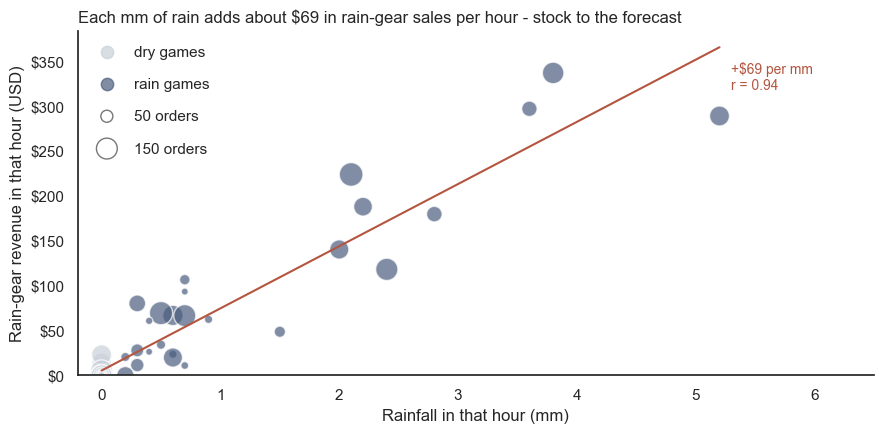

52 game-hours; rain-gear share of orders: dry 0.2%, rain 8.0%


In [6]:
gh = (df.assign(rain_gear=df['revenue'].where(df['category'] == 'RainGear', 0))
        .groupby(['game', 'weather', 'hour'])
        .agg(rain_mm=('rain_mm', 'first'),
             orders=('revenue', 'size'),
             rain_gear=('rain_gear', 'sum'))
        .reset_index())

fig, ax = plt.subplots(figsize=(9, 4.5))
for weather, color in [('dry', GRAY), ('rain', BLUE)]:
    d = gh[gh['weather'] == weather]
    ax.scatter(d['rain_mm'], d['rain_gear'], s=d['orders'] * 1.5, color=color, alpha=0.7,
               edgecolor='white')
    ax.scatter([], [], s=80, color=color, alpha=0.7, label=f'{weather} games')

slope, intercept = np.polyfit(gh['rain_mm'], gh['rain_gear'], 1)
xs = np.linspace(0, gh['rain_mm'].max(), 50)
ax.plot(xs, intercept + slope * xs, color=RUST, lw=1.5)
r = gh[['rain_mm', 'rain_gear']].corr().iloc[0, 1]
ax.text(xs[-1] + 0.1, intercept + slope * xs[-1] - 15, f'+${slope:,.0f} per mm\nr = {r:.2f}',
        color=RUST, fontsize=10, va='top')

for s, lab in [(50, '50 orders'), (150, '150 orders')]:
    ax.scatter([], [], s=s * 1.5, color='none', edgecolor='#777', label=lab)
ax.legend(frameon=False, loc='upper left', labelspacing=1.2)
ax.set_xlim(-0.2, gh['rain_mm'].max() * 1.25)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(lambda y, _: f'${y:,.0f}')
finish(ax,
       f'Each mm of rain adds about ${slope:.0f} in rain-gear sales per hour - stock to the forecast',
       xlabel='Rainfall in that hour (mm)', ylabel='Rain-gear revenue in that hour (USD)')
plt.show()

share = df['category'].eq('RainGear').groupby(df['weather']).mean()
print(f'{len(gh)} game-hours; rain-gear share of orders: dry {share["dry"]:.1%}, rain {share["rain"]:.1%}')

**Caption:** Each dot is one game-hour, sized by total orders so the busy (more trustworthy) hours stand out. Rain-gear revenue is near zero in dry games and rises roughly linearly with rainfall in rainy ones, so ponchos should be stocked against the hourly forecast, front-loaded to the 15:00-18:00 storm window, rather than at a flat level every game.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {}
print('--- chart 1 (category)')
scores['chart 1 (category)'] = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)
print('\n--- chart 2 (hour)')
scores['chart 2 (hour)'] = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)
print('\n--- chart 3 (zone)')
scores['chart 3 (zone)'] = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)
print('\n--- chart 4 (distribution)')
# x-axis clipped at $80 to keep the bulk readable; disclosed on the chart, so still honest
scores['chart 4 (distribution)'] = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)
print('\n--- chart 5 (your choice)')
# dry-game points pile up at x=0; readable, but overlap there is not fully avoidable
scores['chart 5 (your choice)'] = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)
print()

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

--- chart 1 (category)
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

--- chart 2 (hour)
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

--- chart 3 (zone)
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

--- chart 4 (distribution)
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

--- chart 5 (your choice)
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

chart 1 (category)         6/6  [ok]
chart 2 (hour)

### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

**a)** Chart 3 changed my mind.
From the raw totals I assumed Zone A was the strongest zone, since it brings in about half of all revenue.
Normalizing by capacity flipped that: A has the lowest spend per seat ($0.74 per game vs $1.15 in C), so A's lead comes from its size, not from its fans buying more.
That suggests A may be under-served (long lines, too few stands) rather than our best performer.
Chart 2 was the hardest to title, because the data says "peak at 14:00-15:00" but the useful message is a staffing window, so the title had to translate the peak into a start and end time.

**b)** The raw view is right when the question is about absolute volume: how many registers, staff and inventory each zone needs on game day, or which zone contributes most to the budget.
Those decisions scale with total dollars and transactions, regardless of why the volume is there.
The per-capacity view is right when the question is about performance or opportunity: comparing zones of different sizes fairly, deciding where a new stand or premium product would pay off, or checking whether a zone is under-served.
Showing raw totals for that question would just rank the zones by seat count and hide that Zone C fans spend the most each.